# Camelyon17-WILDS: Comparison of CNN and ResNet18

**ELE680 — Group 7 | Tumor Detection across Hospitals**

## Objective

Compare the official test results of CNN and ResNet18 trained with and without data augmentation. The results below are taken from the four completed experiments. This notebook presents the recorded metrics and plots; it does not train or evaluate the models again.

## Experimental setup

The experiments use the Camelyon17-WILDS dataset for binary tumor classification in histopathology image patches. The four configurations are CNN and ResNet18, each trained with and without data augmentation.

The comparison uses the official held-out test results recorded in the individual notebooks. In-distribution (ID) and out-of-distribution (OOD) validation results are discussed separately from test performance.

## 1. Official test results

| Model | Data augmentation | Test accuracy | Test ROC-AUC |
|:--|:--|--:|--:|
| CNN | No | 85.39% | 0.9280 |
| CNN | Yes | **91.22%** | **0.9552** |
| ResNet18 | No | 61.45% | 0.6526 |
| ResNet18 | Yes | 81.16% | 0.9451 |

All four models were evaluated on the official test split containing **85,054 images**. The CNN baseline checkpoint was selected at epoch 13 and the ResNet18 baseline checkpoint at epoch 9. The augmented CNN and ResNet18 checkpoints were both selected at **epoch 16**. Values are rounded for presentation.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Official test metrics recorded in the four experiment notebooks
results = pd.DataFrame([
    {"Architecture": "CNN", "Augmentation": "No", "Test accuracy (%)": 85.39, "Test ROC-AUC": 0.9280},
    {"Architecture": "CNN", "Augmentation": "Yes", "Test accuracy (%)": 91.22, "Test ROC-AUC": 0.9552},
    {"Architecture": "ResNet18", "Augmentation": "No", "Test accuracy (%)": 61.45, "Test ROC-AUC": 0.6526},
    {"Architecture": "ResNet18", "Augmentation": "Yes", "Test accuracy (%)": 81.16, "Test ROC-AUC": 0.9451},
])
results

,Architecture,Augmentation,Test accuracy (%),Test ROC-AUC
0,CNN,No,85.39,0.9280
1,CNN,Yes,91.22,0.9552
2,ResNet18,No,61.45,0.6526
3,ResNet18,Yes,81.16,0.9451


## 2. Test accuracy comparison

The following figure compares test accuracy for the four configurations.

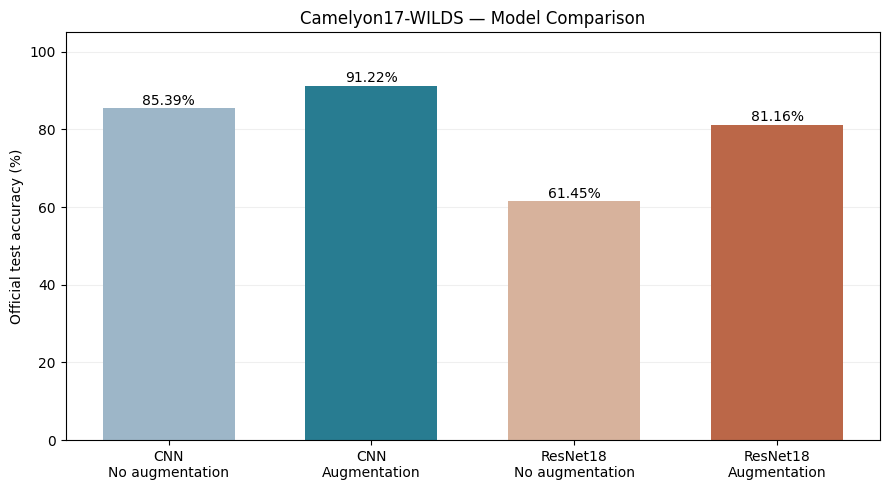

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
labels = ["CNN\nNo augmentation", "CNN\nAugmentation", "ResNet18\nNo augmentation", "ResNet18\nAugmentation"]
colors = ["#9db6c8", "#287c91", "#d7b29c", "#bb6748"]
bars = ax.bar(labels, results["Test accuracy (%)"], color=colors, width=0.65)
for bar, value in zip(bars, results["Test accuracy (%)"]):
    ax.text(bar.get_x() + bar.get_width()/2, value + 1, f"{value:.2f}%", ha="center", fontsize=10)
ax.set_ylim(0, 105)
ax.set_ylabel("Official test accuracy (%)")
ax.set_title("Camelyon17-WILDS — Model Comparison")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 3. Difference with data augmentation

For each architecture, the difference is calculated by subtracting the test accuracy without augmentation from the test accuracy with augmentation. Differences are reported in percentage points (pp).

In [4]:
comparison = pd.DataFrame([
    {"Architecture": "CNN", "Without augmentation (%)": 85.39, "With augmentation (%)": 91.22},
    {"Architecture": "ResNet18", "Without augmentation (%)": 61.45, "With augmentation (%)": 81.16},
])

comparison["Improvement (pp)"] = comparison["With augmentation (%)"] - comparison["Without augmentation (%)"]

comparison.round(2)

,Architecture,Without augmentation (%),With augmentation (%),Improvement (pp)
0,CNN,85.39,91.22,5.83
1,ResNet18,61.45,81.16,19.71


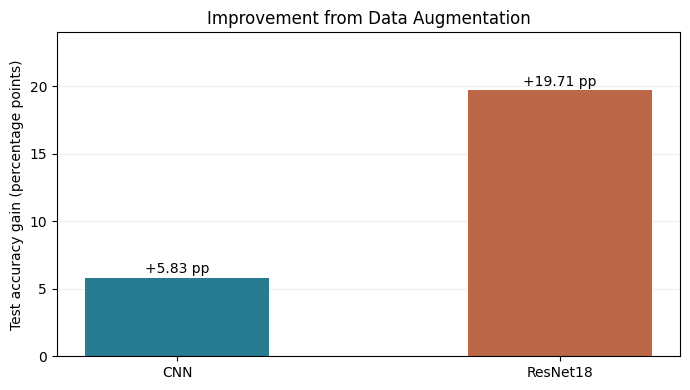

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(comparison["Architecture"], comparison["Improvement (pp)"], color=["#287c91", "#bb6748"], width=0.48)
for bar, value in zip(bars, comparison["Improvement (pp)"]):
    ax.text(bar.get_x() + bar.get_width()/2, value + 0.35, f"+{value:.2f} pp", ha="center")
ax.set_ylim(0, 24)
ax.set_ylabel("Test accuracy gain (percentage points)")
ax.set_title("Improvement from Data Augmentation")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 4. ROC-AUC comparison

The ROC-AUC values below are from the official test evaluations recorded for each model.

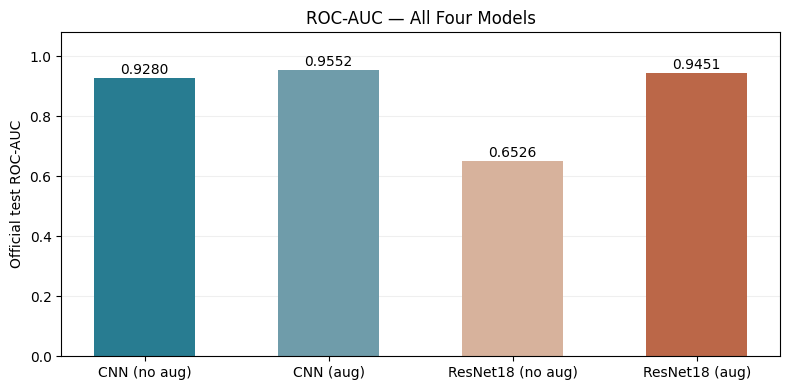

In [6]:
auc_results = results.dropna(subset=["Test ROC-AUC"]).copy()
auc_labels = auc_results["Architecture"] + " (" + auc_results["Augmentation"].map({"Yes": "aug", "No": "no aug"}) + ")"
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(auc_labels, auc_results["Test ROC-AUC"], color=["#287c91", "#6f9caa", "#d7b29c", "#bb6748"], width=0.55)
for bar, value in zip(bars, auc_results["Test ROC-AUC"]):
    ax.text(bar.get_x() + bar.get_width()/2, value + 0.012, f"{value:.4f}", ha="center")
ax.set_ylim(0, 1.08)
ax.set_ylabel("Official test ROC-AUC")
ax.set_title("ROC-AUC — All Four Models")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 5. Validation and test performance

The augmented CNN checkpoint (epoch 16) recorded **98.78% ID validation accuracy** and **91.13% OOD validation balanced accuracy**. Its official test accuracy was **91.22%**.

The augmented ResNet18 checkpoint (epoch 16) recorded **98.86% ID validation accuracy** and **88.89% OOD validation accuracy**. Its official test accuracy was **81.16%**.

The lower OOD validation and test scores, compared with ID validation, show that performance varies between the dataset splits.

## 6. Discussion

**Effect of augmentation.** CNN test accuracy increased from **85.39% to 91.22%**, a difference of **5.83 percentage points**. ResNet18 test accuracy increased from **61.45% to 81.16%**, a difference of **19.71 percentage points**. The recorded ROC-AUC also increased for both architectures.

**Model comparison.** CNN with augmentation obtained the highest test accuracy (**91.22%**) and ROC-AUC (**0.9552**) among the four configurations. ResNet18 with augmentation obtained **81.16%** accuracy and **0.9451** ROC-AUC.

**Performance across splits.** Both augmented models performed better on ID validation than on OOD validation and the official test set. 

## 7. Conclusion

In the recorded experiments, **CNN with augmentation** achieved the highest official test accuracy (**91.22%**) and ROC-AUC (**0.9552**). Both CNN and ResNet18 had higher official test accuracy with augmentation than without it. The largest accuracy difference was observed for ResNet18 (**19.71 percentage points**).